# 03 · Temas → libros

Recomendación top-10 para 53 334 lectores (partición temporal por lector) y el experimento de **libros
nuevos**: 960 libros retirados de todo el entrenamiento, recomendados solo con sus temas predichos.

In [1]:
import json
import sys

import pandas as pd
from book_topics import MODULE

from common import data_dir, setup_style

setup_style()
d = data_dir(MODULE)
P = d.parent
report = json.loads((P / "resultados" / "metrics.json").read_text())
b = report["parte_b"]
v1 = json.loads((P / "resultados" / "metrics_v1_sin_desempate.json").read_text())["parte_b"]
print(
    "colaborativo elegido en validación:",
    b["colaborativo_elegido"],
    "| α del híbrido:",
    b["alpha_hibrido"],
)
tab = pd.DataFrame(b["modelos"]).T
tab["ndcg@10 (1.ª ejecución, sin desempate)"] = pd.DataFrame(v1["modelos"]).T["ndcg@10"]
tab.round(4)

colaborativo elegido en validación: PureSVD (k=100) | α del híbrido: 0.75


,ndcg@10,cobertura,percentil_popularidad,"ndcg@10 (1.ª ejecución, sin desempate)"
popularidad,0.0505,0.0056,99.9255,0.0505
colaborativo,0.0712,0.1505,96.5752,0.0712
temas,0.0179,0.6131,72.6826,0.0098
hibrido,0.0723,0.1552,96.5460,0.0723


**Lectura.** El colaborativo (PureSVD) mejora a la popularidad en NDCG@10 (0,071 frente a 0,051) y
el híbrido apenas lo supera (0,072). El recomendador **solo por temas** queda muy abajo en NDCG (0,018)
pero tiene la mayor cobertura del catálogo (61 % frente a 15 %) y recomienda libros mucho menos
populares (percentil 73 frente a 97). Es un recomendador de *descubrimiento*, no de acierto.

La columna de la 1.ª ejecución muestra el efecto del desempate por popularidad (peso < 1e-9) que se
agregó *después* de ver los resultados: temas pasó de 0,010 a 0,018, y los demás no cambiaron. Es un
ajuste post hoc y se reporta como tal.

## 1. Por cuartil de historial (H2)

H2 híbrido − colaborativo (Q1): Δ = +0.0005 IC [+0.0001, +0.0008] p_Holm = 0.0130


,popularidad,colaborativo,temas,hibrido
Q1,0.0399,0.0640,0.0147,0.0645
Q2,0.0461,0.0690,0.0163,0.0700
Q3,0.0539,0.0749,0.0185,0.0760
Q4,0.0619,0.0768,0.0221,0.0786


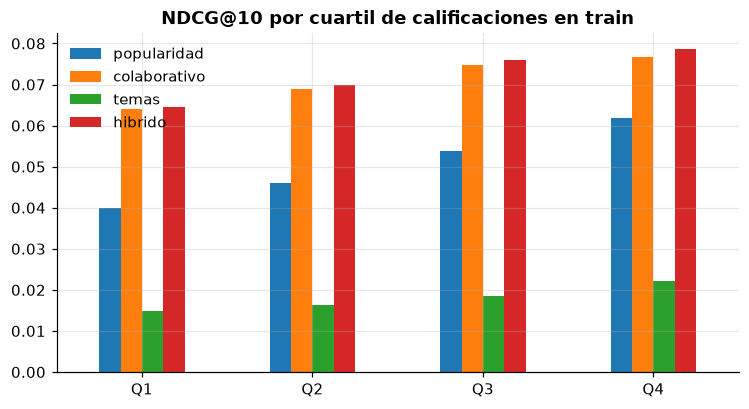

In [2]:
hist = pd.DataFrame(b["por_historial"]).T
hist.plot.bar(figsize=(8, 4), rot=0, title="NDCG@10 por cuartil de calificaciones en train")
h2 = report["hipotesis"]["H2"]
lo, hi = h2["ci"]
print(
    f"H2 híbrido − colaborativo (Q1): Δ = {h2['diff']:+.4f} IC [{lo:+.4f}, {hi:+.4f}]",
    f"p_Holm = {h2['p_holm']:.4f}",
)
hist.round(4)

**Lectura.** H2 es estadísticamente significativa (Δ = +0,0005, p_Holm = 0,013) pero **irrelevante en
la práctica**: medio milésimo de NDCG. Con 13 000 lectores por cuartil, el bootstrap detecta diferencias
minúsculas. Lo que sí muestra la tabla es que todos los modelos mejoran con más historial, y que la
ventaja del colaborativo sobre la popularidad es mayor en Q1 (+0,024) que en Q4 (+0,015).

## 2. Libros nuevos (H3)

In [3]:
new = report["libros_nuevos"]
h3 = report["hipotesis"]["H3"]
print(new)
lo, hi = h3["ci"]
print(
    f"H3 temas − popularidad: Δ = {h3['diff']:+.4f} IC [{lo:+.4f}, {hi:+.4f}]",
    f"p_Holm = {h3['p_holm']:.4f} → apoya: {h3['apoya_hipotesis']}",
)

{'n_libros_nuevos': 960, 'n_usuarios': 52343, 'ndcg@10': {'temas_predichos': 0.042076735793288564, 'popularidad (optimista)': 0.1430287066361786, 'aleatorio': 0.009117957666575523}}
H3 temas − popularidad: Δ = -0.1010 IC [-0.1027, -0.0993] p_Holm = 0.0015 → apoya: False


**Lectura.** H3 **no se apoya**: para 960 libros que el sistema nunca vio en calificaciones, recomendar
por temas predichos (0,042) es 4,6 veces mejor que al azar (0,009) pero queda muy debajo de la
popularidad (0,143). Ojo: esa popularidad es *optimista*, porque usa las calificaciones de los libros
nuevos, que en un arranque en frío real no existirían. Aun contra esa referencia inalcanzable, los temas
son la única señal disponible el día 1 y claramente aportan sobre el azar.

## 3. La CLI con lectores inventados

In [4]:
import subprocess

for args in (
    ["recomendar", "--lei", "Dune", "Foundation", "The Hobbit"],
    ["recomendar", "--lei", "Pride and Prejudice", "Jane Eyre", "--no-me-gusto", "Twilight"],
):
    out = subprocess.run(
        [sys.executable, "-m", "book_topics", *args], capture_output=True, text=True
    ).stdout
    print("$", " ".join(args), "\n" + out)

$ recomendar --lei Dune Foundation The Hobbit 
1. Dune Messiah (Dune Chronicles #2) — porque te gustan: Clásicos, Fantasía, Ciencia ficción
2. The Great Dune Trilogy   — porque te gustan: Clásicos, Fantasía, Ciencia ficción
3. The Fellowship of the Ring (The Lord of the Rings, #1) — porque te gustan: Clásicos, Fantasía
4. The Two Towers (The Lord of the Rings, #2) — porque te gustan: Clásicos, Fantasía
5. The Return of the King (The Lord of the Rings, #3) — porque te gustan: Clásicos, Fantasía
6. The Lord of the Rings (The Lord of the Rings, #1-3) — porque te gustan: Clásicos, Fantasía
7. The Time Machine — porque te gustan: Clásicos, Ciencia ficción
8. Stranger in a Strange Land — porque te gustan: Clásicos, Ciencia ficción
9. The War of the Worlds — porque te gustan: Clásicos, Ciencia ficción
10. 2001: A Space Odyssey (Space Odyssey, #1) — porque te gustan: Clásicos, Ciencia ficción



$ recomendar --lei Pride and Prejudice Jane Eyre --no-me-gusto Twilight 
1. Mansfield Park — porque te gustan: Romance, Literatura, Clásicos
2. The Complete Novels — porque te gustan: Romance, Literatura, Clásicos
3. Emma — porque te gustan: Romance, Literatura, Clásicos
4. Anna Karenina — porque te gustan: Romance, Literatura, Clásicos
5. Love in the Time of Cholera — porque te gustan: Romance, Literatura, Clásicos
6. Persuasion — porque te gustan: Romance, Literatura, Clásicos
7. Northanger Abbey — porque te gustan: Romance, Literatura, Clásicos
8. A Room with a View — porque te gustan: Romance, Literatura, Clásicos
9. The Age of Innocence — porque te gustan: Romance, Literatura, Clásicos
10. Doctor Zhivago — porque te gustan: Romance, Literatura, Clásicos

